ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Device: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

... (13 outputs left out)

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .



Generating Prompt 1, Seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_1_seed_42.png


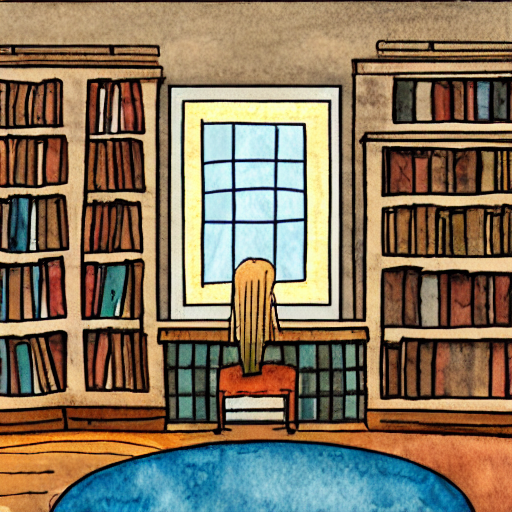


Generating Prompt 1, Seed 43


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_1_seed_43.png


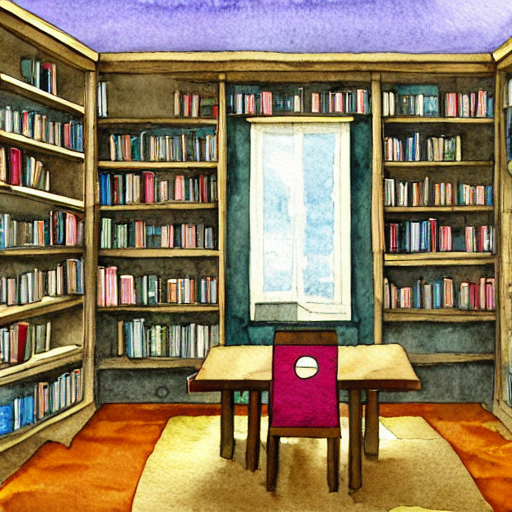


Generating Prompt 2, Seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_2_seed_42.png


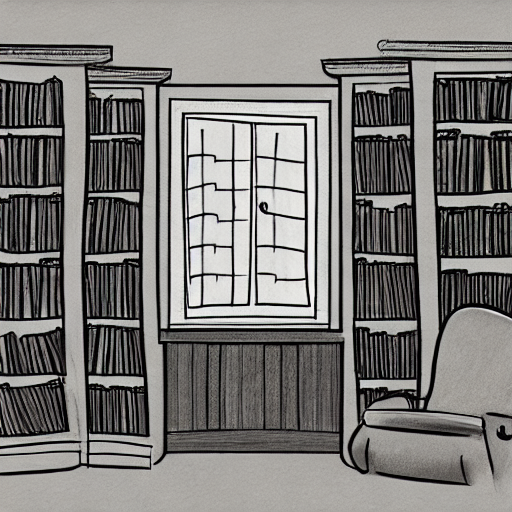


Generating Prompt 2, Seed 43


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_2_seed_43.png


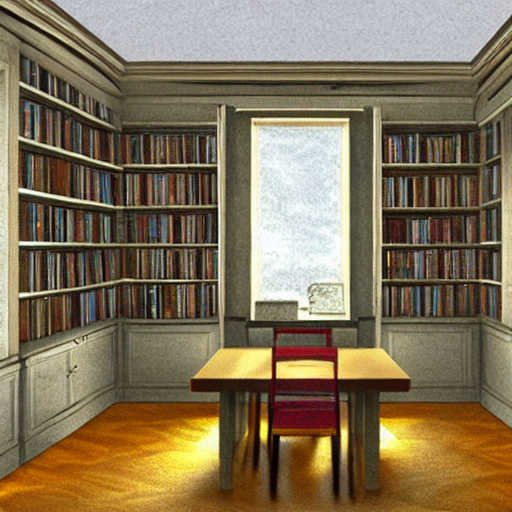


Generation completed!
Total images generated: 4


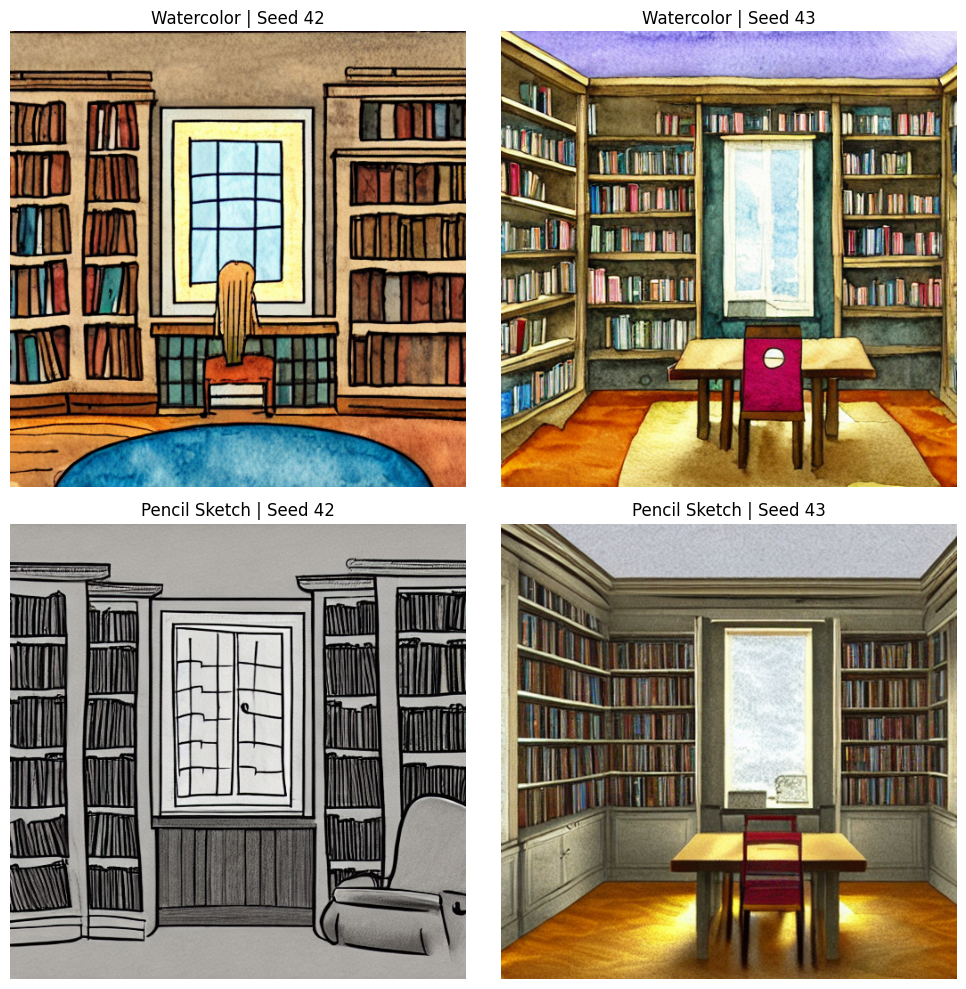

Output folder: /content/lab_outputs
Device: cuda


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .



Generating Prompt 1, Seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_1_seed_42.png


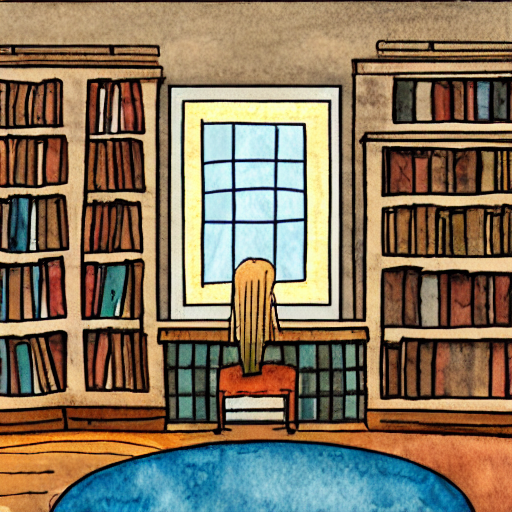


Generating Prompt 1, Seed 43


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_1_seed_43.png


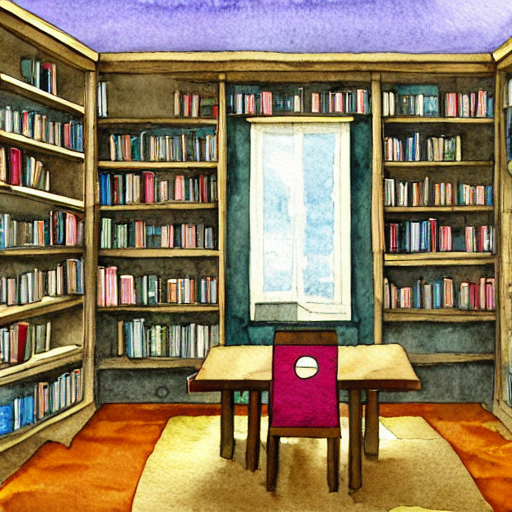


Generating Prompt 2, Seed 42


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_2_seed_42.png


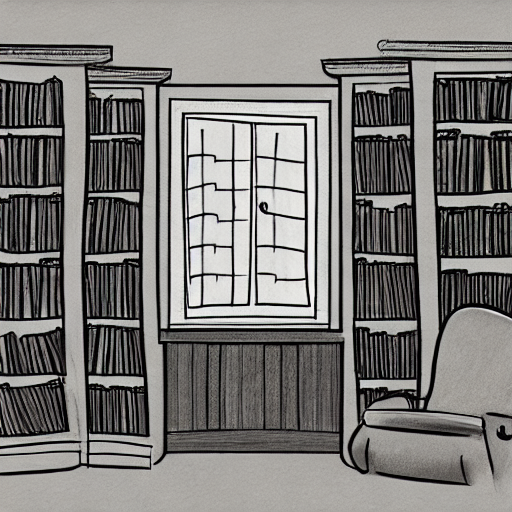


Generating Prompt 2, Seed 43


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: library_prompt_2_seed_43.png


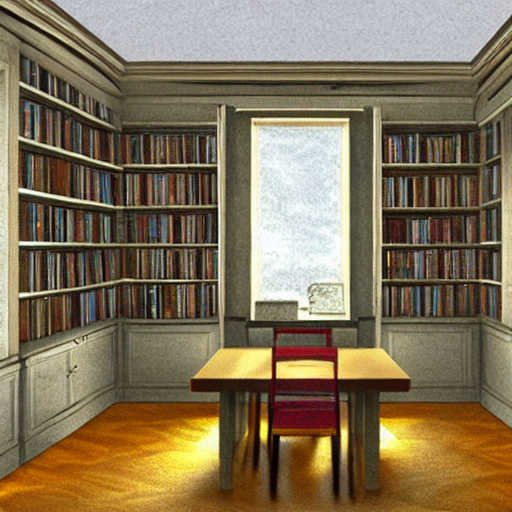


Generation completed!
Total images generated: 4


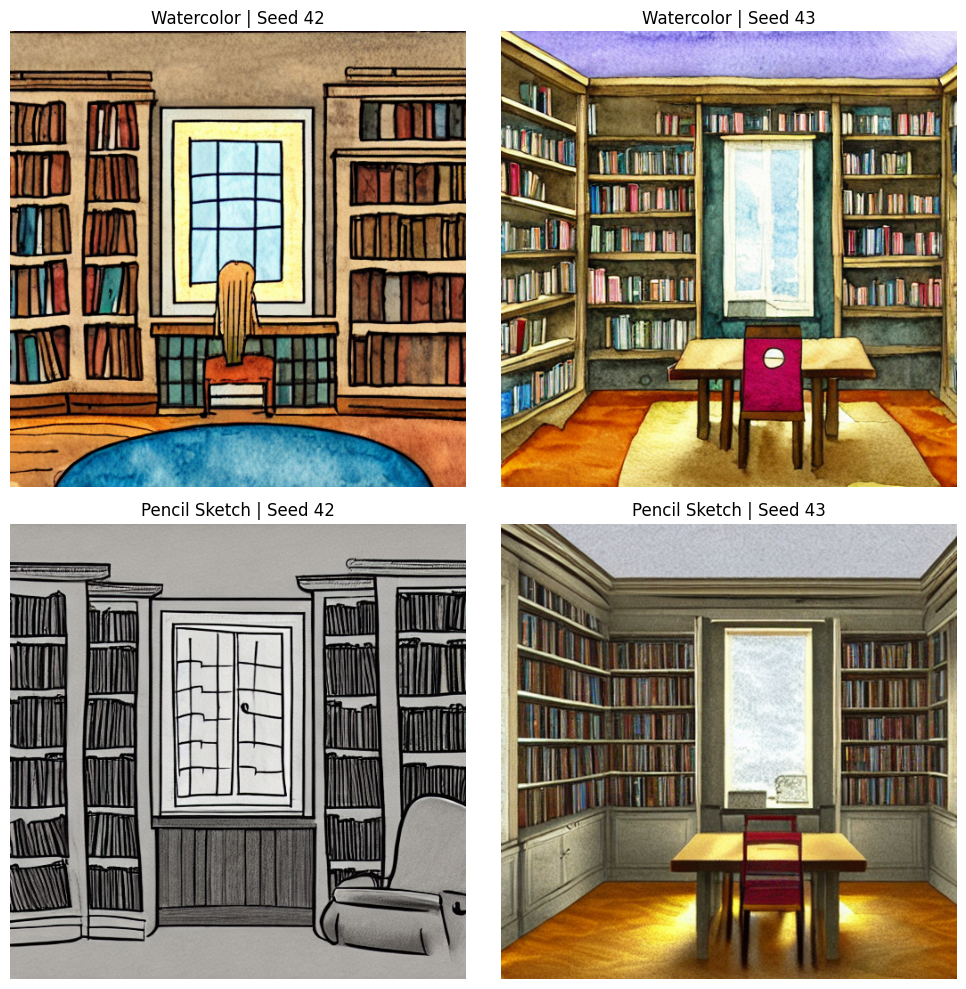

Output folder: /content/lab_outputs


In [2]:

%pip install -q "diffusers==0.39.0" "transformers>=4.51,<5" accelerate safetensors

import torch
import random
from pathlib import Path
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline
from IPython.display import display

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

out = Path("lab_outputs")
out.mkdir(exist_ok=True)

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

if device == "cuda":
    dtype = torch.float16
else:
    dtype = torch.float32

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype,
    safety_checker=None
)

pipe = pipe.to(device)
pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=False)

prompts = [
    "A small library with a reading table, wide view, watercolor illustration",
    "A small library with a reading table, wide view, pencil sketch"
]

results = []

for i, prompt in enumerate(prompts, 1):
    for seed in (42, 43):
        print(f"\nGenerating Prompt {i}, Seed {seed}")

        generator = torch.Generator(device=device).manual_seed(seed)

        with torch.inference_mode():
            image = pipe(
                prompt,
                width=512,
                height=512,
                num_inference_steps=25,
                guidance_scale=7.5,
                generator=generator
            ).images[0]

        filename = f"library_prompt_{i}_seed_{seed}.png"
        image.save(out / filename)

        results.append((prompt, seed, image))
        print("Saved:", filename)
        display(image)

print("\nGeneration completed!")
print("Total images generated:", len(results))

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, (prompt, seed, image) in zip(axes.flat, results):
    ax.imshow(image)
    style = "Watercolor" if "watercolor" in prompt else "Pencil Sketch"
    ax.set_title(f"{style} | Seed {seed}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Output folder:", out.resolve())
